Shape: (21613, 6)
Missing values: 0
Shape after filtering: (21589, 6)
   Neighborhood  Houses  Avg_Price  Median_Price
24        98039      50  2160607.0     1892500.0
3         98004     316  1356585.0     1152500.0
25        98040     282  1194230.0      993750.0
48        98112     269  1095499.0      915000.0
41        98102     103   901331.0      720000.0


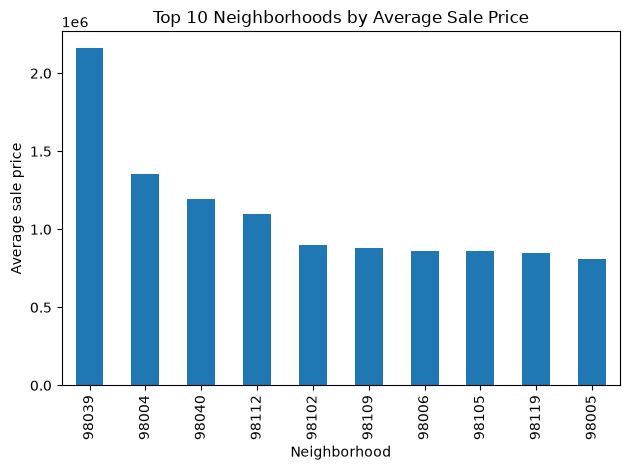

In [1]:
# Practical 10: Data Wrangling
# Aim: Clean, transform, filter, merge and aggregate real-estate data for analysis.
# Dataset: RealEstate_Prices.csv (house sales)

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("RealEstate_Prices.csv", dtype={"zipcode": str})
df = df[["date", "price", "bedrooms", "bathrooms", "sqft_living", "zipcode"]]
df.columns = ["SaleDate", "SalePrice", "Bedrooms", "Bathrooms", "Area_sqft", "Neighborhood"]
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())

df["SaleDate"] = pd.to_datetime(df["SaleDate"], format="%Y%m%dT%H%M%S")
df = df.dropna()
df = df[(df["SalePrice"] > 0) & (df["Bedrooms"].between(1, 8))]
print("Shape after filtering:", df.shape)

df["Year"] = df["SaleDate"].dt.year
df["Price_per_sqft"] = (df["SalePrice"] / df["Area_sqft"]).round(2)
df["Size"] = pd.cut(df["Bedrooms"], [0, 2, 4, 8], labels=["Small", "Medium", "Large"])

summary = df.groupby("Neighborhood")["SalePrice"].agg(["count", "mean", "median"]).round(0)
summary = summary.rename(columns={"count": "Houses", "mean": "Avg_Price", "median": "Median_Price"})
summary = summary.reset_index()
print(summary.sort_values("Avg_Price", ascending=False).head())

df = df.merge(summary[["Neighborhood", "Avg_Price"]], on="Neighborhood")
df = pd.get_dummies(df, columns=["Size"])

top = summary.sort_values("Avg_Price", ascending=False).head(10)
top.plot(x="Neighborhood", y="Avg_Price", kind="bar", legend=False,
         title="Top 10 Neighborhoods by Average Sale Price")
plt.ylabel("Average sale price")
plt.tight_layout()
plt.show()

df.to_csv("RealEstate_Wrangled.csv", index=False)